# The Beta distribution

## Normalizing the distribution: the beta function

For $x,y>0$ the *beta function* is defined by

$$
\mathcal{B}(x,y):=\int_0^1 t^{x-1}(1-t)^{y-1}dt
$$

See the discusion about the gamma distribution for details on the $\Gamma$ function. 

**Lemma:** We have $\mathcal{B}(x,y)=\Gamma(x)\Gamma(y)/\Gamma(x+y)$, where $\Gamma$ denotes the $\Gamma$ function.

*Proof:*
We have

\begin{align}
    \Gamma(x)\Gamma(y) 
    = \int_0^\infty u^{x-1}e^{-u}du  \int_0^\infty v^{y-1}e^{-v}dv
    = \int_0^\infty \int_0^\infty u^{x-1}v^{y-1}e^{-(u+v)} du dv
\end{align}

and $u=st$ and $v=s(1-t)$ yields $u+v=s$ and $u/(u+v)=t$. 
Thus, 
\begin{align}
    \Gamma(x)\Gamma(y) 
    = \int_0^\infty \int_0^\infty u^{x-1}v^{y-1}e^{-(u+v)} du dv
    = \int_0^\infty \int_0^1 (st)^{x-1}(s(1-t))^{y-1}e^{-s} sdt ds
    = \int_0^\infty s^{x+y-1}e^{-s} ds   \int_0^1 t^{x-1}(1-t)^{y-1}dt
    =\Gamma(x+y)\mathcal{B}(x,y). 
\end{align}



<>:24: SyntaxWarning: invalid escape sequence '\m'
<>:24: SyntaxWarning: invalid escape sequence '\m'
C:\Users\Till Hauser\AppData\Local\Temp\ipykernel_41908\570446153.py:24: SyntaxWarning: invalid escape sequence '\m'
  ax.set_zlabel("$\mathcal{B}(x,y)$")


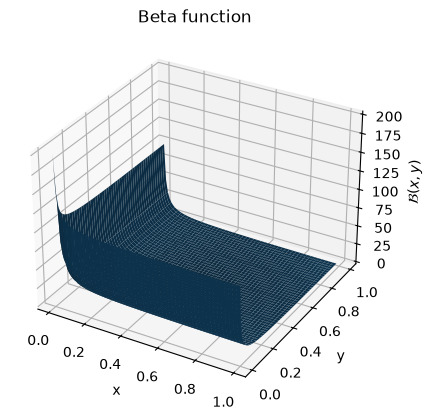

In [289]:
from math import gamma as g

def beta_function(x,y): 
    return g(x)*g(y)/g(x+y)

from matplotlib import pyplot as plt
import numpy as np


x_range = np.arange(0.01, 1, 0.01)
y_range = np.arange(0.01, 1, 0.01)

fig = plt.figure()
ax = fig.add_subplot(111, projection="3d")

X,Y = np.meshgrid(x_range,y_range)
beta_function = np.vectorize(beta_function)
Z = beta_function(X,Y)

ax.plot_surface(X, Y, Z)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("$\mathcal{B}(x,y)$")

plt.title('Beta function')
plt.show()


## Back to the beta distribution

For (shape) parameters $\alpha, \beta>0$ the *beta distribution* is defined by the probability density function

$$
f(x) = 
\begin{cases}
    \frac{1}{\mathcal{B}(\alpha,\beta)}x^{\alpha-1}(1-x)^{\beta-1}&,\text{for } 0\leq x \leq 1\\ 
    0 &, \text{otherwise}. 
\end{cases}
$$

**Remark:**
The beta distribution is a suitable model for the random behavior of percentages and proportions.

We write $X\sim \operatorname{Beta}(\alpha, \beta)$. 

**Proposition:** For $X\sim \operatorname{Beta}(\alpha,\beta)$ we have
1) $\mathbb{E}[X]= \frac{\alpha}{\alpha+\beta}$ and
2) $\operatorname{Var}[X] = \frac{\alpha\beta}{(\alpha+\beta)^2(\alpha+\beta+1)}$.
3) $M_X(t)= 1+\sum_{k=1}^\infty \left(\prod_{r=0}^{k-1}\frac{\alpha+r}{\alpha+\beta+r}\right)\frac{t^k}{k!}$

*Proof:* Include? 



# Some Visualization

Note that the pdf does not need to be coded by hand and can be found in the `skipy` module via 
`from scipy.stats import beta as beta_dist` and `beta_dist.pdf(x, alpha, beta)`. 

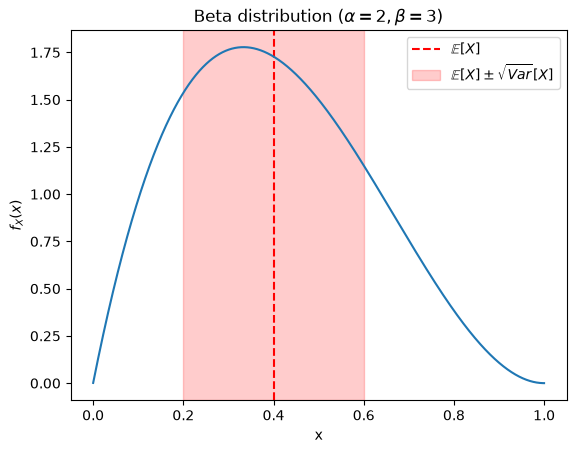

In [290]:
from math import gamma as g
from math import sqrt
from matplotlib import pyplot as plt
import numpy as np

alpha, beta = 2,3

def beta_function(x,y): 
    return g(x)*g(y)/g(x+y)

def beta_pdf(alpha=1,beta=1): 
    """Returns the probability density function of the beta distribution. 
    For this the shape parameters alpha>0 and beta>0 need to be specified."""
    def f(x): 
        if x <=0 or x>=1: 
            return 0
        return g(alpha+beta)/(g(alpha)*g(beta))*x**(alpha-1)*(1-x)**(beta-1)
    return f

f = beta_pdf(alpha=alpha,beta=beta)

#### Alternatively from scipy ####
from scipy.stats import beta as beta_dist
#f = lambda x : beta_dist.pdf(x, alpha, beta)


mean = alpha/(alpha+beta)
var = (alpha*beta)/((alpha+beta)**2*(alpha+beta+1))
std = sqrt(var)
mean_label = rf'$\mathbb{{E}}[X]$'
plt.axvline(x=mean,color='red',linestyle='--',label=mean_label)
std_label = rf'$\mathbb{{E}}[X]\pm\sqrt{{Var}}[X]$'
plt.axvspan(mean - std,mean + std,color='red',alpha=0.2,label=std_label)

step = 0.0001
x_range = np.arange(step, 1, step)

plt.plot(x_range, [f(x) for x in x_range])
plt.title('Beta distribution '+fr'($\alpha = {alpha}, \beta = {beta}$)')
plt.xlabel('x')
plt.ylabel('$f_X(x)$')
plt.legend()
plt.show()



## Simulation

The beta distribution can be simulated with `numpy` as follows. 

0.4811240310966326


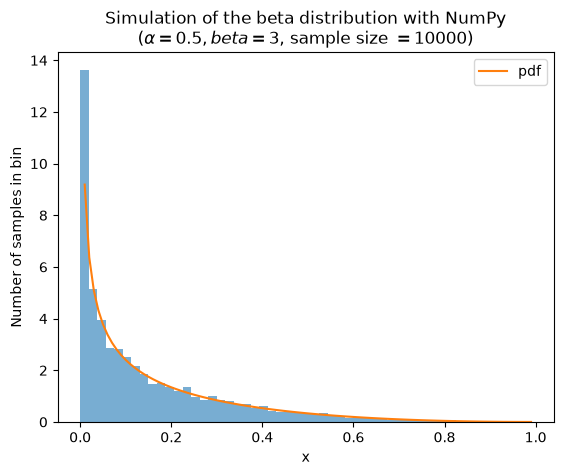

In [291]:
import numpy as np
import scipy
from matplotlib import pyplot as plt

random_number_generator = np.random.default_rng()
### A seed can be specified for the random number generator to make it reproducable
# random_number_generator = np.random.default_rng(seed=42)

alpha = 0.5
beta = 3

x = random_number_generator.beta(alpha, beta)
print(x)

# Also samples can be generated
size = 10000
samples = random_number_generator.beta(alpha, beta, size=size)


# Visualization of the samples
number_bins = 50
plt.hist(samples, bins = number_bins, density= True, alpha=0.6)

step = 0.01
x_range = np.arange(step, 1, step)
f = lambda x : scipy.stats.beta.pdf(x, alpha, beta)
plt.plot(x_range, f(x_range), label="pdf")

plt.title('Simulation of the beta distribution with NumPy\n'+rf'($\alpha={alpha}, beta={beta}$, sample size $= {size}$)')
plt.xlabel('x')
plt.ylabel('Number of samples in bin')
plt.legend()
plt.show()

It can also be simulated with `scipy` by `scipy.stats.beta.rvs(alpha, beta, size=size)`. 

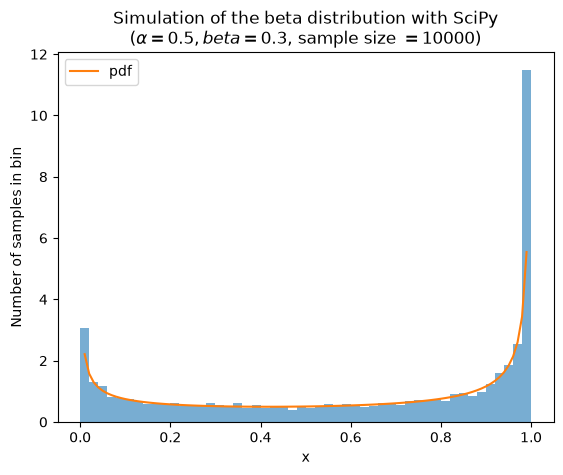

In [292]:
from scipy.stats import beta as beta_dist
import matplotlib.pyplot as plt

alpha, beta = 0.5, 0.3
size = 10000

samples = beta_dist.rvs(alpha, beta, size=size)
plt.hist(samples, bins=50, density=True, alpha=0.6)

step = 0.01
x_range = np.arange(step, 1, step)
f = lambda x : beta_dist.pdf(x, alpha, beta)
plt.plot(x_range, f(x_range), label="pdf")

plt.title('Simulation of the beta distribution with SciPy\n'+rf'($\alpha={alpha}, beta={beta}$, sample size $= {size}$)')
plt.xlabel('x')
plt.ylabel('Number of samples in bin')
plt.legend()
plt.show()